# Triángulos y compresión en el USD/CLP — Backtest

**Torneo FEN–Banco Itaú "¿Sube o baja el dólar mañana?"** · Juan Pablo Díaz Cerda y Rodrigo Gutierrez Albornoz

Este notebook reproduce el backtest completo de la estrategia: señales, contabilidad (bruto, carry y costos), estadísticas de trading, gráficos y la señal del día. Todo se calcula aquí mismo con el detector congelado de `src/triangulos.py`.

**Para ejecutarlo:** con la base en `data/base_usdclp.xlsx`, abrir este notebook desde la raíz del repositorio y correr todas las celdas (*Run All*). Tarda unos minutos, porque recalcula la señal de cada día con la serie cortada en ese día, igual que en tiempo real.

**Contenido**
1. Modelos y supuestos
2. Mecanismo de ejecución
3. Backtest: estadísticas de trading
4. Gráficos: curva de resultado, holdout, drawdown y operaciones
5. Lectura de convicción y señal del día

## 1. Modelos y supuestos

### El modelo de la estrategia final
La estrategia usa **un solo modelo**: un detector algorítmico de **triángulos convergentes** sobre el OHLC diario del USD/CLP. Un triángulo es una zona en que los máximos bajan y los mínimos suben: el rango se comprime. El detector no se estima con los datos del peso; su geometría está fijada por reglas numéricas, todas medidas en ATR (rango verdadero promedio de 14 días).

Cada día, con datos hasta ese día, el detector:
1. **Encuentra pivotes**: máximos y mínimos locales, con ventana de 3 días a cada lado. Un pivote solo se usa 3 días después de ocurrir, así que no hay información del futuro.
2. **Traza rectas** de techo y base entre pares de pivotes (unos 15.000 candidatos por día).
3. **Filtra** los candidatos: duración de 25 a 220 días, ancho inicial ≥ 1,3 veces el final, altura de 1,5 a 8 ATR, ≥ 85% de cierres dentro, ≥ 5 toques y ápice cercano. Sobreviven en promedio 2,9 triángulos por día.
4. **Traduce** el estado de cada triángulo en una posición (ver sección 2).

### Cómo se combinan los modelos
No hay combinación. Se probaron un probit ordenado con variables macro y de mercado, una doble validación probit + triángulo, una señal post-cierre de Nueva York, reglas de tendencia y tres modelos de aprendizaje automático (logit, bosque aleatorio y gradient boosting). Todos fueron **descartados** antes del holdout porque no generaron valor neto de costos. El registro completo está en `experimentos/registro_experimentos.csv`.

La **probabilidad de alza** que se publica no viene de otro modelo. Es la frecuencia de acierto de cada nivel de exposición en la ventana de selección: 51,2% para ±1, 57,1% para ±3 y 50,9% (frecuencia de alzas) cuando la posición es 0.

### Supuestos clave
| Supuesto | Valor |
|---|---|
| Precio | `USDCLP Curncy` PX_OPEN/HIGH/LOW/LAST (Bloomberg BGN onshore, cierre del mercado formal local) |
| Muestra útil | Desde 2004: antes el OHLC es plano (máximo = mínimo) |
| Feriados | Se eliminan los días con rango cero y cierre igual al anterior (precio rancio) |
| Carry | TPM (`CHOVCHOV`) − Fed funds (`FEDL01`, rezagada un día), act/360 por días corridos. Largo paga, corto recibe |
| Costos | 0,5 CLP por dólar por cada unidad de cambio de posición (≈ 5 pb). Pasar de 0 a +3 paga 3 veces |
| Referencias | Comprar siempre = +3 todos los días · Siempre +1 · No operar = 0 |
| Ventanas | Selección: ene 2023 – 4 abr 2025 · Holdout: 7 abr 2025 – 5 oct 2026 (el modelo no se tocó después de abrirlo) |
| Variante congelada | RA-SB-BC-OA: ruptura con 3 cierres + 0,45 ATR, salida por objetivo/stop/60 días, rebote con vela de rechazo, rotación libre |

## 2. Mecanismo de ejecución

### Momento: al cierre, close-to-close
- La señal del día *t* se calcula **después del cierre de Santiago del día *t***, con el OHLC de `USDCLP Curncy` hasta *t* inclusive.
- La posición se toma **al cierre de *t*** y se mantiene hasta el **cierre de *t+1***.
- El retorno de la jornada es **cierre a cierre**: $(S_{t+1}-S_t)/S_t$ con `PX_LAST`.
- **No** se usa la apertura ni el **dólar observado**. El dólar observado se publica en la mañana y refleja la jornada anterior, así que no se usa ni para la señal ni para el retorno.

Resultado diario por unidad de nocional:
$$\pi_{t+1} = x_t\,\frac{S_{t+1}-S_t}{S_t} \;-\; x_t\,\frac{\text{TPM}_t-\text{FF}_{t-1}}{360}\,\Delta d_t \;-\; 0{,}5\,\frac{|x_t-x_{t-1}|}{S_t}$$

### Qué gatilla cada posición
| Posición | Caso | Gatillo (al cierre de *t*) |
|---|---|---|
| **+3** | `RETEST_ARRIBA` | Hubo ruptura alcista, el mínimo volvió a ≤ 0,6 ATR del techo roto y el precio cerró otra vez afuera. Dura 3 días |
| **+1** | `RUPTURA_ARRIBA` | 3 cierres seguidos sobre el techo por más de 0,45 ATR. Se mantiene mientras la ruptura esté vigente |
| **+1** | `BASE` | Cierre a ≤ 0,6 ATR sobre la base con vela de rechazo (cierre > apertura y en la mitad superior del rango del día) |
| **−1** | `TECHO` | Cierre a ≤ 0,6 ATR bajo el techo con vela de rechazo (cierre < apertura y en la mitad inferior del rango) |
| **−1** | `RUPTURA_ABAJO` | 3 cierres seguidos bajo la base por más de 0,45 ATR |
| **−3** | `RETEST_ABAJO` | Simétrico al retest alcista. Dura 3 días |
| **0** | — | Sin triángulo vigente, ápice vencido, ruptura fallida o triángulos con señales opuestas |

**Salidas de una ruptura** (la primera que ocurra): (i) el precio recorre la altura inicial del triángulo; (ii) cierra de vuelta dentro del triángulo (pasa a 0 ese día, y si en 2 días no vuelve a cerrar afuera la ruptura muere); (iii) cierra más de 1 ATR adentro de la recta rota; (iv) pasan 60 días hábiles.

### Cómo replicarlo en el monitor del laboratorio
1. Agregar a la base la fila del día *t* con `PX_OPEN`, `PX_HIGH`, `PX_LOW` y `PX_LAST` de `USDCLP Curncy`. La señal necesita los cuatro campos, no solo el cierre. TPM y Fed funds solo se usan para el carry.
2. Correr `python estrategia.py ruta/a/la/base.xlsx` después del cierre.
3. Leer `salidas/senal_del_dia.json`: el campo `posicion` es la exposición para la jornada siguiente (cierre *t* → cierre *t+1*).
4. No se modifica ningún parámetro durante el monitoreo.

## 3. Backtest: estadísticas de trading

Configuración y carga de datos.

In [24]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAIZ = Path.cwd()
if not (RAIZ / "src" / "triangulos.py").exists():
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ / "src"))
import triangulos as tg

BASE = RAIZ / "data" / "base_usdclp.xlsx"
CFG = {"ruptura": "A", "salida": "B", "base": "C"}      # variante RA-SB-BC-OA (congelada)
COSTO_CLP = 0.50          # costo por dólar y por unidad de cambio de posición
POS_COMPRAR = 3.0         # "comprar siempre" = +3 todos los días
INICIO = "2023-01-01"
SELECCION = ("2023-01-01", "2025-04-04")
HOLDOUT = ("2025-04-07", "2026-10-05")
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print("Base:", BASE)

Base: /Users/juanpablo/Desktop/quantclp-torneo/data/base_usdclp.xlsx


In [25]:
clp = tg.cargar_usdclp(BASE)
det = tg.Detector(clp)
F = clp.index
tasas = (pd.read_excel(BASE, sheet_name="datos",
                       usecols=["fecha", "CHOVCHOV Index|PX_LAST", "FEDL01 Index|PX_LAST"])
           .rename(columns={"CHOVCHOV Index|PX_LAST": "tpm", "FEDL01 Index|PX_LAST": "ff"})
           .assign(fecha=lambda x: pd.to_datetime(x["fecha"]))
           .set_index("fecha").sort_index())
tasas["ff"] = tasas["ff"].shift(1)          # la Fed funds se publica al día siguiente
tasas = tasas.ffill().reindex(F, method="ffill")
print(f"USD/CLP: {F[0].date()} a {F[-1].date()} · {len(F)} días hábiles")

USD/CLP: 2004-01-01 a 2026-10-06 · 5628 días hábiles


Señales históricas. Cada señal se calcula con la serie **cortada en su propio día**: es exactamente lo que la estrategia habría producido en tiempo real.

In [26]:
idx = np.where(F >= pd.Timestamp(INICIO))[0]
reg = []
for k in idx:
    tris = det.detectar(k)
    p, caso, tipo = tg.senal(det, tris, k, CFG)
    reg.append({"fecha": F[k], "k": k, "pos": p, "caso": caso, "tipo": tipo})
sen = pd.DataFrame(reg).set_index("fecha")
print(f"{len(sen)} señales calculadas, cada una con datos hasta su propio día.")
sen["pos"].value_counts().sort_index()

950 señales calculadas, cada una con datos hasta su propio día.


pos
-3      6
-1    119
 0    534
 1    270
 3     21
Name: count, dtype: int64

Contabilidad diaria de la estrategia y de las tres referencias: bruto, carry y costos.

In [27]:
h = sen.iloc[:-1].copy()                    # el último día aún no tiene retorno t+1
kk = h["k"].to_numpy()
S0 = det.C[kk]
ret = det.C[kk + 1] / S0 - 1
dias = (F[kk + 1] - F[kk]).days.to_numpy()
carry_u = -((tasas["tpm"] - tasas["ff"]).to_numpy()[kk] / 100 / 360) * dias


def resultado(p):
    dp = np.abs(np.diff(p, prepend=0.0))
    return pd.DataFrame({"bruto": p * ret, "carry": p * carry_u,
                         "costos": -dp * COSTO_CLP / S0, "pos": p, "ret": ret}, index=h.index)


ESTR = {"Triángulos": h["pos"].to_numpy(float),
        "Comprar siempre (+3)": np.full(len(h), POS_COMPRAR),
        "Siempre +1": np.ones(len(h)),
        "No operar": np.zeros(len(h))}
RES = {n: resultado(p).assign(neto=lambda x: x["bruto"] + x["carry"] + x["costos"])
       for n, p in ESTR.items()}
TRAMOS = {"Selección (ene 2023 – abr 2025)": SELECCION,
          "Holdout (abr 2025 – oct 2026)": HOLDOUT,
          "Todo (desde ene 2023)": (INICIO, str(h.index[-1].date()))}
if h.index[-1] > pd.Timestamp(HOLDOUT[1]):
    TRAMOS["En vivo (después del holdout)"] = (str((pd.Timestamp(HOLDOUT[1]) + pd.Timedelta(days=1)).date()),
                                               str(h.index[-1].date()))

**Estadísticas por tramo.** Neto = bruto + carry + costos, acumulado en % del nocional por unidad de posición. Volatilidad y Sharpe anualizados con 252 días. Caída máxima sobre el neto acumulado. % de aciertos: días con posición en que el signo coincide con el del retorno del dólar. Una operación es una secuencia de días seguidos con posición del mismo signo, e incluye su costo de cierre.

El tramo que cuenta es el **holdout**: la ventana de selección se usó para elegir la variante, así que no es evidencia fuera de muestra.

In [28]:
def operaciones(r):
    """Una operación = días seguidos con posición del mismo signo. Incluye el costo de cierre."""
    s = np.sign(r["pos"].to_numpy())
    neto = r["neto"].to_numpy()
    ops, i, n = [], 0, len(s)
    while i < n:
        if s[i] == 0:
            i += 1
            continue
        j = i
        while j + 1 < n and s[j + 1] == s[i]:
            j += 1
        pnl = neto[i:j + 1].sum()
        if j + 1 < n and s[j + 1] == 0:      # costo de cerrar, cobrado el día que pasa a 0
            pnl += neto[j + 1]
        ops.append({"inicio": r.index[i], "fin": r.index[j], "lado": "larga" if s[i] > 0 else "corta",
                    "dias": j - i + 1, "pnl_%": pnl * 100})
        i = j + 1
    return pd.DataFrame(ops)


def estadisticas(r):
    x = r["neto"]
    acum = x.cumsum()
    dd = (acum - acum.cummax().clip(lower=0)).min()
    activo = r["pos"] != 0
    ops = operaciones(r)
    return pd.Series({
        "Bruto %": r["bruto"].sum() * 100,
        "Carry %": r["carry"].sum() * 100,
        "Costos %": r["costos"].sum() * 100,
        "Neto %": x.sum() * 100,
        "Vol. anual %": x.std() * np.sqrt(252) * 100,
        "Sharpe": x.mean() / x.std() * np.sqrt(252) if x.std() > 0 else np.nan,
        "Caída máx. %": dd * 100,
        "% días con posición": activo.mean() * 100,
        "% aciertos (días con posición)": (np.sign(r["pos"]) == np.sign(r["ret"]))[activo].mean() * 100
        if activo.any() else np.nan,
        "N° operaciones": len(ops),
        "% operaciones ganadoras": (ops["pnl_%"] > 0).mean() * 100 if len(ops) else np.nan,
    })


TABLAS = {}
for tramo, (a, b) in TRAMOS.items():
    TABLAS[tramo] = pd.DataFrame({n: estadisticas(r.loc[a:b]) for n, r in RES.items()}).T
    print("\n" + tramo)
    display(TABLAS[tramo])


Selección (ene 2023 – abr 2025)


,Bruto %,Carry %,Costos %,Neto %,Vol. anual %,Sharpe,Caída máx. %,% días con posición,% aciertos (días con posición),N° operaciones,% operaciones ganadoras
Triángulos,18.95,-0.96,-3.11,14.88,10.31,0.64,-15.80,45.98,51.71,13.00,38.46
Comprar siempre (+3),48.22,-20.12,-0.17,27.93,40.26,0.31,-33.82,100.00,50.87,1.00,100.00
Siempre +1,16.07,-6.71,-0.06,9.31,13.42,0.31,-11.27,100.00,50.87,1.00,100.00
No operar,0.00,0.00,0.00,0.00,0.00,NaN,0.00,0.00,NaN,0.00,NaN



Holdout (abr 2025 – oct 2026)


,Bruto %,Carry %,Costos %,Neto %,Vol. anual %,Sharpe,Caída máx. %,% días con posición,% aciertos (días con posición),N° operaciones,% operaciones ganadoras
Triángulos,13.75,-0.29,-1.73,11.73,7.85,1.00,-5.95,40.58,58.82,12.00,58.33
Comprar siempre (+3),-1.43,-3.46,0.00,-4.89,35.63,-0.09,-48.47,100.00,49.60,1.00,0.00
Siempre +1,-0.48,-1.15,0.00,-1.63,11.88,-0.09,-16.16,100.00,49.60,1.00,0.00
No operar,0.00,0.00,0.00,0.00,0.00,NaN,0.00,0.00,NaN,0.00,NaN



Todo (desde ene 2023)


,Bruto %,Carry %,Costos %,Neto %,Vol. anual %,Sharpe,Caída máx. %,% días con posición,% aciertos (días con posición),N° operaciones,% operaciones ganadoras
Triángulos,32.69,-1.25,-4.84,26.61,9.41,0.75,-15.80,43.84,54.33,25.00,48.00
Comprar siempre (+3),46.79,-23.58,-0.17,23.04,38.47,0.16,-53.71,100.00,50.37,1.00,100.00
Siempre +1,15.60,-7.86,-0.06,7.68,12.82,0.16,-17.90,100.00,50.37,1.00,100.00
No operar,0.00,0.00,0.00,0.00,0.00,NaN,0.00,0.00,NaN,0.00,NaN


## 4. Gráficos

### Curva de resultado desde 2023

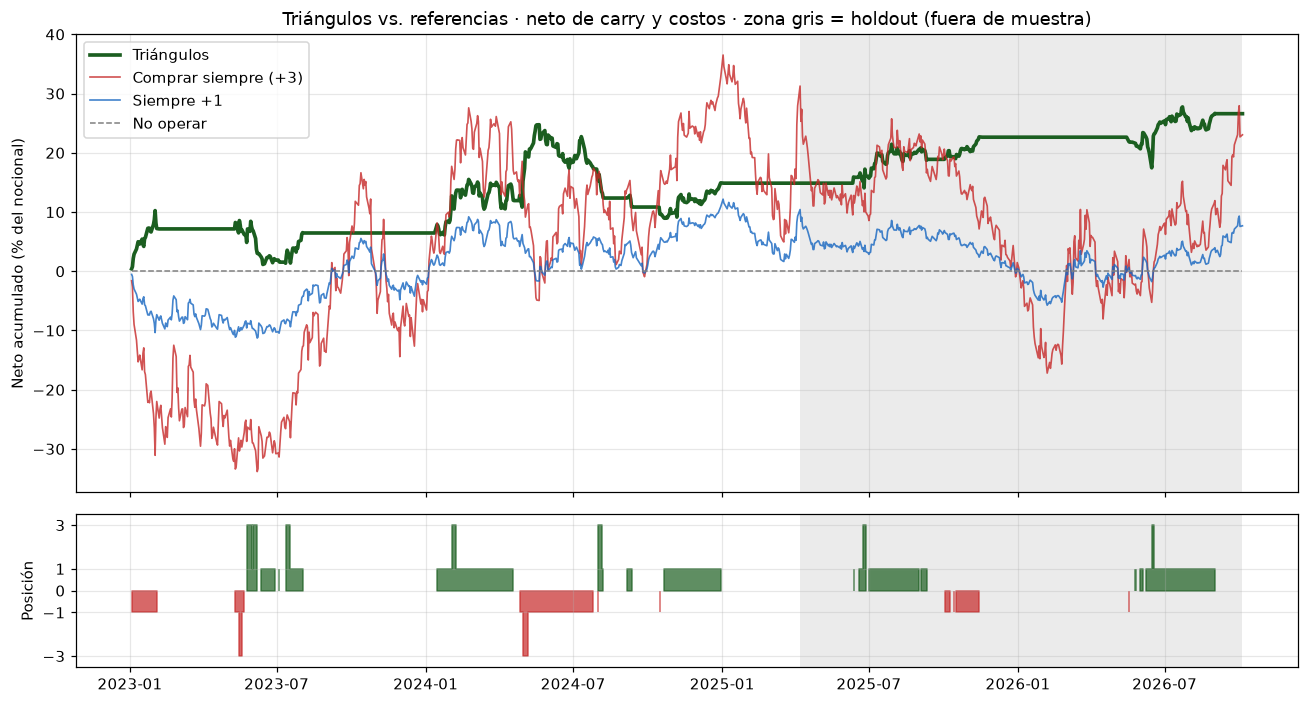

In [29]:
fig, (ax, ax2) = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True,
                              gridspec_kw={"height_ratios": [3, 1]})
estilos = {"Triángulos": dict(lw=2.4, color="#1b5e20"),
           "Comprar siempre (+3)": dict(lw=1.1, color="#c62828", alpha=0.8),
           "Siempre +1": dict(lw=1.1, color="#1565c0", alpha=0.8),
           "No operar": dict(lw=1.0, color="0.5", ls="--")}
for n, r in RES.items():
    ax.plot(r.index, r["neto"].cumsum() * 100, label=n, **estilos[n])
for a2 in (ax, ax2):
    a2.axvspan(pd.Timestamp(HOLDOUT[0]), pd.Timestamp(HOLDOUT[1]), color="0.85", alpha=0.5, lw=0)
ax.set_ylabel("Neto acumulado (% del nocional)")
ax.set_title("Triángulos vs. referencias · neto de carry y costos · zona gris = holdout (fuera de muestra)")
ax.legend(loc="upper left")
ax2.fill_between(h.index, h["pos"], where=h["pos"] > 0, step="post", color="#1b5e20", alpha=0.7)
ax2.fill_between(h.index, h["pos"], where=h["pos"] < 0, step="post", color="#c62828", alpha=0.7)
ax2.set_ylim(-3.5, 3.5); ax2.set_yticks([-3, -1, 0, 1, 3]); ax2.set_ylabel("Posición")
plt.tight_layout(); plt.show()

### El holdout por sí solo (base 100)

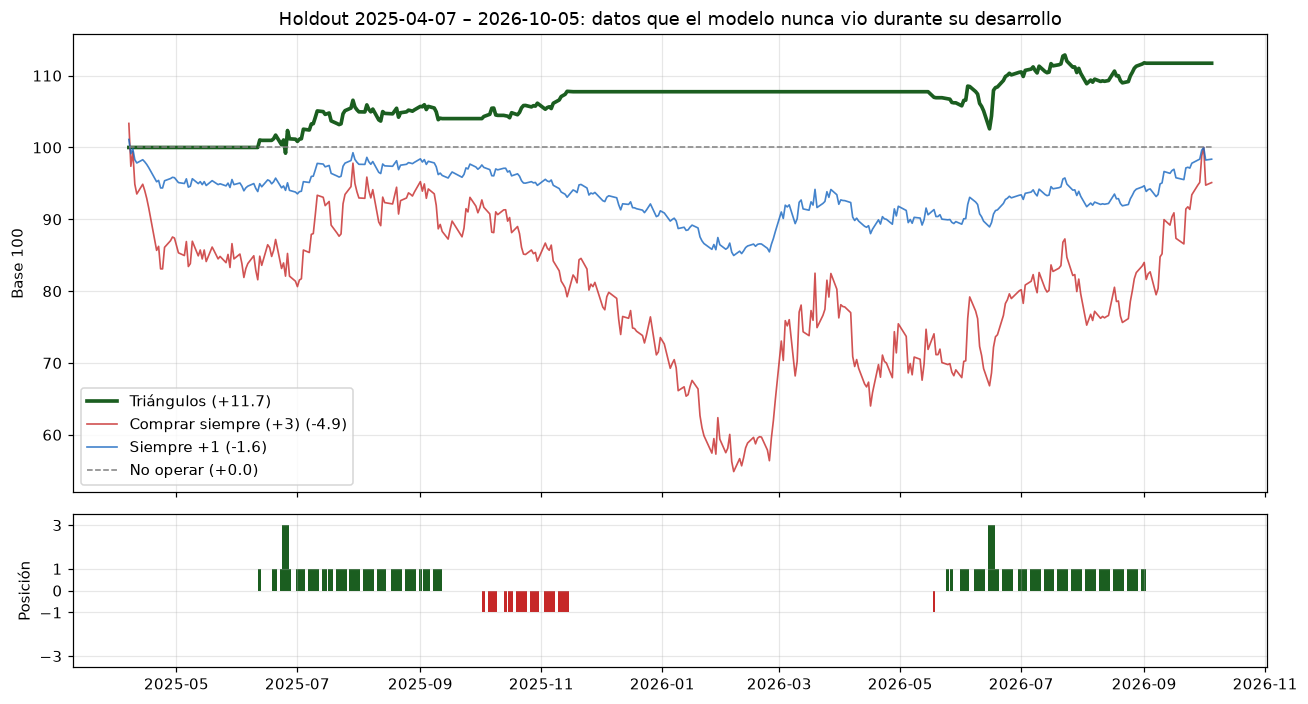

In [30]:
a, b = HOLDOUT
fig, (ax, ax2) = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True,
                              gridspec_kw={"height_ratios": [3, 1]})
for n, r in RES.items():
    x = r.loc[a:b, "neto"]
    ax.plot(x.index, 100 + x.cumsum() * 100, label=f"{n} ({x.sum() * 100:+.1f})", **estilos[n])
ax.set_ylabel("Base 100"); ax.legend(loc="lower left")
ax.set_title(f"Holdout {a} – {b}: datos que el modelo nunca vio durante su desarrollo")
pos_h = h.loc[a:b, "pos"]
ax2.bar(pos_h.index, pos_h, width=1.5, color=np.where(pos_h > 0, "#1b5e20", "#c62828"))
ax2.set_ylim(-3.5, 3.5); ax2.set_yticks([-3, -1, 0, 1, 3]); ax2.set_ylabel("Posición")
plt.tight_layout(); plt.show()

### Drawdown en el holdout

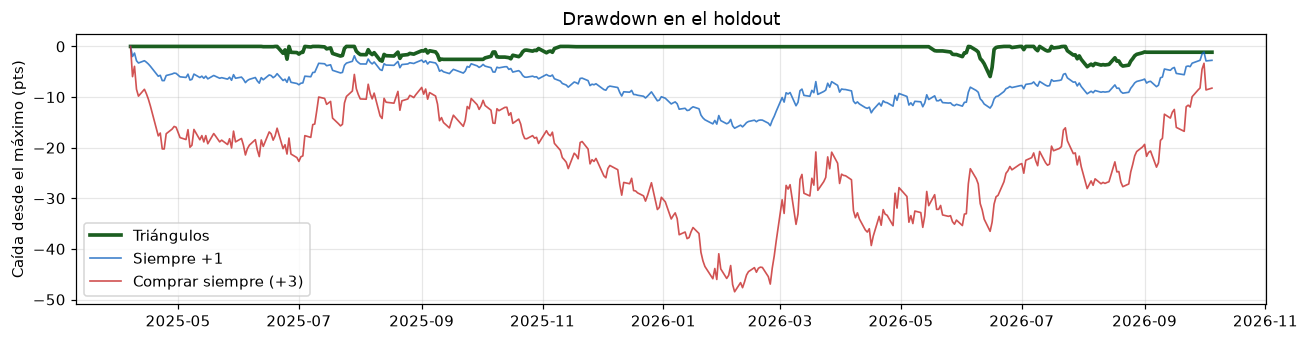

In [31]:
fig, ax = plt.subplots(figsize=(12, 3.2))
for n in ["Triángulos", "Siempre +1", "Comprar siempre (+3)"]:
    acum = RES[n].loc[a:b, "neto"].cumsum() * 100
    ax.plot(acum.index, acum - acum.cummax().clip(lower=0), label=n, **estilos[n])
ax.set_ylabel("Caída desde el máximo (pts)"); ax.set_title("Drawdown en el holdout"); ax.legend()
plt.tight_layout(); plt.show()

### Operaciones del holdout

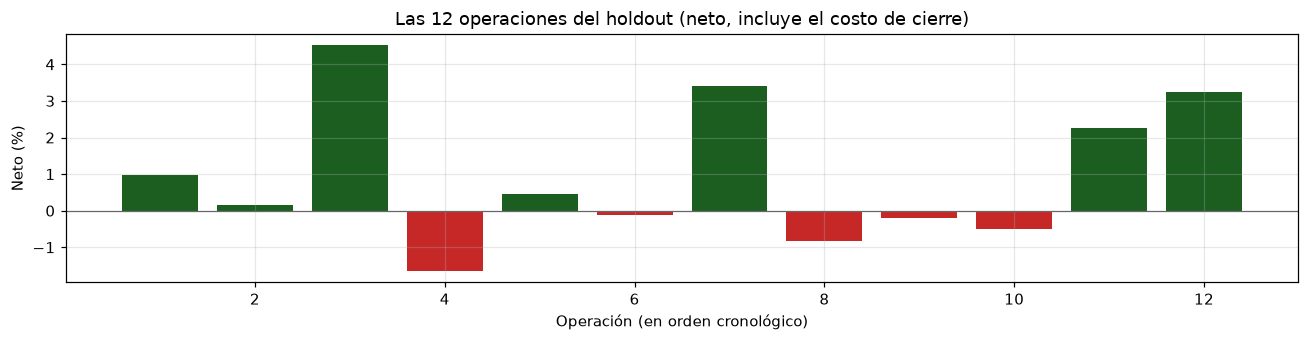

,inicio,fin,lado,dias,pnl_%
0,2025-06-12,2025-06-12,larga,1,0.99
1,2025-06-19,2025-06-27,larga,7,0.16
2,2025-07-01,2025-09-01,larga,43,4.52
3,2025-09-03,2025-09-11,larga,7,-1.65
4,2025-10-03,2025-10-09,corta,5,0.45
5,2025-10-14,2025-10-14,corta,1,-0.11
6,2025-10-16,2025-11-14,corta,21,3.40
7,2026-05-18,2026-05-18,corta,1,-0.84
8,2026-05-25,2026-05-25,larga,1,-0.20
9,2026-05-27,2026-05-27,larga,1,-0.51


In [32]:
ops_h = operaciones(RES["Triángulos"].loc[a:b])
fig, ax = plt.subplots(figsize=(12, 3.2))
ax.bar(range(1, len(ops_h) + 1), ops_h["pnl_%"],
       color=np.where(ops_h["pnl_%"] > 0, "#1b5e20", "#c62828"))
ax.axhline(0, color="0.4", lw=0.8)
ax.set_xlabel("Operación (en orden cronológico)"); ax.set_ylabel("Neto (%)")
ax.set_title(f"Las {len(ops_h)} operaciones del holdout (neto, incluye el costo de cierre)")
plt.tight_layout(); plt.show()
ops_h

## 5. Lectura de convicción y señal del día

### ¿La estrategia sabe cuándo sabe? (holdout)
Resultado por nivel de exposición. La última columna muestra cuánto ganó o perdió *siempre +1* en esos mismos días: en la abstención, es la pérdida que se evitó (si es negativa) o la ganancia que se dejó pasar (si es positiva).

In [33]:
r = RES["Triángulos"].loc[a:b].assign(caso=h.loc[a:b, "caso"])
uno = RES["Siempre +1"].loc[a:b, "neto"]
r["nivel"] = np.select([r["pos"].abs() == 3, r["pos"].abs() == 1], ["±3 (máxima)", "±1 (media)"],
                       "0 (abstención)")
conv = (r.assign(acierto=np.where(r["pos"] != 0, np.sign(r["pos"]) == np.sign(r["ret"]), np.nan),
                 uno=uno)
          .groupby("nivel")
          .agg(dias=("neto", "size"), acierto_pct=("acierto", "mean"),
               neto_pct=("neto", "sum"), siempre_uno_esos_dias_pct=("uno", "sum")))
conv["acierto_pct"] *= 100; conv["neto_pct"] *= 100; conv["siempre_uno_esos_dias_pct"] *= 100
conv

,dias,acierto_pct,neto_pct,siempre_uno_esos_dias_pct
nivel,,,,
0 (abstención),224,NaN,-0.64,-5.06
±1 (media),147,58.50,7.54,1.74
±3 (máxima),6,66.67,4.83,1.68


### Señal del día
Posición para la jornada siguiente, calculada con el último cierre de la base. Es la misma salida que `estrategia.py` guarda en `salidas/senal_del_dia.json`.

In [34]:
_sel = (h.index >= pd.Timestamp(SELECCION[0])) & (h.index <= pd.Timestamp(SELECCION[1]))
_p = h["pos"].to_numpy()
ACIERTO = {n: float(np.mean(np.sign(_p[m]) == np.sign(ret[m])))
           for n, m in {1: _sel & (np.abs(_p) == 1), 3: _sel & (np.abs(_p) == 3)}.items()}
P_ALZA = float(np.mean(ret[_sel] > 0))
hoy = sen.iloc[-1]
pos = int(hoy["pos"])
prob = P_ALZA if pos == 0 else (ACIERTO[abs(pos)] if pos > 0 else 1 - ACIERTO[abs(pos)])
pd.Series({"Cierre usado": str(sen.index[-1].date()),
           "USD/CLP cierre": round(float(det.C[int(hoy['k'])]), 2),
           "Posición para la jornada siguiente": pos,
           "Caso": hoy["caso"],
           "P(sube) estimada": f"{prob:.1%}"})

Cierre usado                          2026-10-06
USD/CLP cierre                            973.95
Posición para la jornada siguiente             0
Caso                                        NADA
P(sube) estimada                           50.9%
dtype: object

## 6. Dónde están los experimentos

Este notebook muestra solo el backtest de la **estrategia final**. Los experimentos que llevaron a elegirla, y las pruebas de robustez posteriores, están en `experimentos/` como scripts numerados que se corren por separado. Cada intento queda anotado en `experimentos/registro_experimentos.csv`, incluidos los descartados.

| Script | Qué responde |
|---|---|
| 02 – 04 | Piloto del detector, grilla de 24 variantes (2005–2018) y selección de la variante (2023 – abr 2025) |
| 04b – 04c | Apertura del holdout con el modelo congelado |
| 04d – 04e | Meses alcistas y bajistas; ventanas de 13 días (horizonte del monitoreo en vivo) |
| 05 – 09 | Modelos descartados: probit ordenado, doble validación, brecha post-cierre y tendencia |
| 10 | La regla congelada aplicada a otras nueve monedas |
| 12 | Diebold-Mariano y bootstrap estacionario |
| 13 | Qué hace la compresión: magnitud vs. dirección de la salida |
| 14 | Anatomía del detector: embudo de filtros y casos reales |
| 15 | Sensibilidad: cada parámetro movido ±20% |
| 16 | Atraso de ejecución, placebos y estadísticas por operación |
| 17 | Correlaciones y banco de aprendizaje automático |
| 18 | Calibración de P(sube) y definiciones alternativas de carry |